# Acquisition Function Visualization (Random IV)

Load one saved active-learning `output_dict` HDF5 file from `iv_acqfn_script.py` and look at a single iteration:
reduced error and best-scale maps, the acquired points, the 3D error map over (col, row, scale), and the acquired
patches with their IV curves. Mirrors `notebooks/STM/vizualize_acfn_analysis_after_normgauss.ipynb`.

The IV script already uses the corrected (point-order) reduction, so the "corrected reduction" section of the STM
notebook is replaced by a sanity check here.

In [1]:
# Make nnerror, the STM helpers and the Random_IV helpers importable from the repo root or from notebooks/Random_IV
from pathlib import Path
import sys

cwd = Path.cwd()
repo_root = cwd if (cwd / "src" / "nnerror").exists() else cwd.parent.parent
for p in (repo_root / "src", repo_root / "notebooks" / "STM", repo_root / "notebooks" / "Random_IV"):
    if str(p.resolve()) not in sys.path:
        sys.path.insert(0, str(p.resolve()))

from nnerror.training_functions import distance_acq_fn
from stm_ms_acqfn_script import Norm_G
from helper_fns import (load_random_iv, smooth_spectra, flatten_image, apply_offset, get_padded_subimages,
                        augment_with_mask, error_3d_html, show_html_iframe)

In [2]:
%matplotlib inline

import re
import sys
from pathlib import Path

import h5py
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd()
iv_dir = cwd / "notebooks" / "Random_IV" if (cwd / "notebooks" / "Random_IV").exists() else cwd
results_dir = iv_dir / "data" / "active_learning_results"

# Run settings (must match the file names written by iv_acqfn_script.py)
model_type = "im2spec"
error_type = "L1"
WS = 32
latent_dim = 5
acquisition_iterations = 50
num_new_points = 5
norm_type = "normgauss"
mask_suffix = "_mask"          # the mask channel is on for both ss and ms in the IV runs
offset = (-12, 7)


def build_result_file(acquisition, scale_type):
    return results_dir / (
        f"al_{model_type}_{error_type}_WS{WS}_latent{latent_dim}_appendpad_"
        f"{acquisition_iterations}iters_{num_new_points}pts_"
        f"{acquisition}acq_{scale_type}_{norm_type}{mask_suffix}_off{offset[0]}_{offset[1]}.h5"
    )


def load_h5_ragged(filename):
    data_dict = {}
    with h5py.File(filename, "r") as f:
        for key in f.keys():
            group = f[key]
            data_dict[key] = [group[str(i)][()] for i in range(len(group))]
    return data_dict


def infer_num_new_points(output_dict, output_file, fallback=5):
    match = re.search(r"_(\d+)pts_", Path(output_file).name)
    if match:
        return int(match.group(1))
    train_indices = output_dict.get("train_indices", [])
    if len(train_indices) > 1:
        return int(len(train_indices[1]) - len(train_indices[0]))
    return fallback


def plot_reduced_errors_and_scales(errors, coords_reduced, aq_indices=None, title_prefix=""):
    """Reduced (minimum over scales) predicted error and the best scale, on image (col, row) axes."""
    rows, cols, scales = coords_reduced[:, 0], coords_reduced[:, 1], coords_reduced[:, 2]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    sc0 = axes[0].scatter(cols, rows, c=errors, s=12)
    axes[0].set_title(f"{title_prefix}Reduced minimum error, mean = {np.mean(errors):.3g}")
    plt.colorbar(sc0, ax=axes[0], label="Minimum predicted error")

    uniq = np.unique(scales)
    sc1 = axes[1].scatter(cols, rows, c=scales, s=12, cmap="viridis", vmin=uniq.min(), vmax=uniq.max())
    axes[1].set_title(f"{title_prefix}Best scale at each point")
    cb = plt.colorbar(sc1, ax=axes[1], label="Best scale (px)")
    cb.set_ticks(uniq)

    if aq_indices is not None and len(aq_indices) > 0:
        aq_indices = np.asarray(aq_indices, dtype=int)
        axes[0].scatter(cols[aq_indices], rows[aq_indices], marker="x", s=120, linewidths=2, c="r",
                        label="Acquisition points")
        axes[0].legend(loc="upper right")

    for ax in axes:
        ax.set_xlabel("col (px)")
        ax.set_ylabel("row (px)")
        ax.set_xlim(0, 127)
        ax.set_ylim(0, 127)
        ax.set_aspect("equal")
    plt.tight_layout()
    plt.show()


scale_type = "ms"            # "ms" or "ss"
acquisition = "distance"     # "distance" or "random"
output_file = build_result_file(acquisition, scale_type)
print(output_file.name, output_file.exists())

al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask_off-12_7.h5 True


In [3]:
output_dict = load_h5_ragged(output_file)
point_coords = output_dict["point_coords"][0]          # (N, 2) (row, col) after the offset
scales_saved = output_dict["scales"][0]
N, S = len(point_coords), len(scales_saved)
print({key: len(value) for key, value in output_dict.items()})
print(f"N = {N} points, scales = {scales_saved.tolist()}")

{'im2spec_test_mismatches': 50, 'point_coords': 1, 'pred_error_test': 50, 'predicted_errors_all': 50, 'recorded_coords': 1, 'reduced_coords': 50, 'reduced_errors': 50, 'reduced_errors_im2spec': 50, 'scales': 1, 'test_indices': 50, 'train_indices': 50}
N = 2001 points, scales = [4, 8, 12, 16, 20, 24, 28, 32]


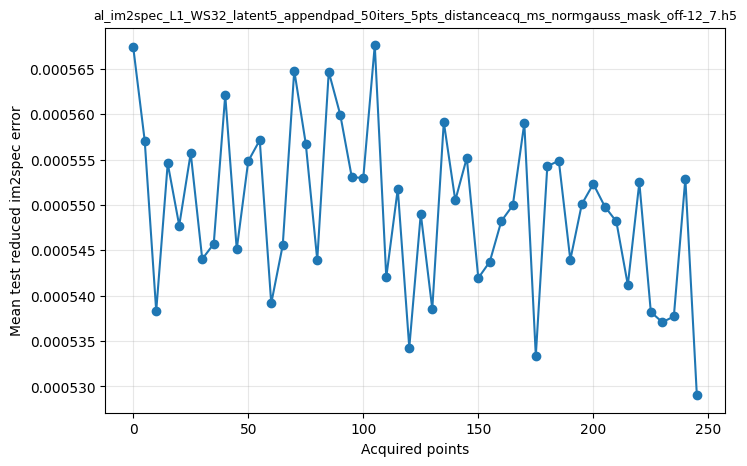

In [4]:
train_indices_arr = output_dict["train_indices"]
test_indices_arr = [indices.astype(int) for indices in output_dict["test_indices"]]
reduced_errors_arr = np.array(output_dict["reduced_errors_im2spec"])
num_saved_iterations = len(reduced_errors_arr)
points_per_iteration = infer_num_new_points(output_dict, output_file)

mean_test_reduced_errors = [np.mean(reduced_errors_arr[i][test_indices_arr[i]]) for i in range(num_saved_iterations)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(num_saved_iterations) * points_per_iteration, mean_test_reduced_errors, marker="o")
ax.set_xlabel("Acquired points")
ax.set_ylabel("Mean test reduced im2spec error")
ax.set_title(Path(output_file).name, fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

# Set plot_iteration

In [5]:
plot_iteration = 1

Plotting iteration 1 from al_im2spec_L1_WS32_latent5_appendpad_50iters_5pts_distanceacq_ms_normgauss_mask_off-12_7.h5


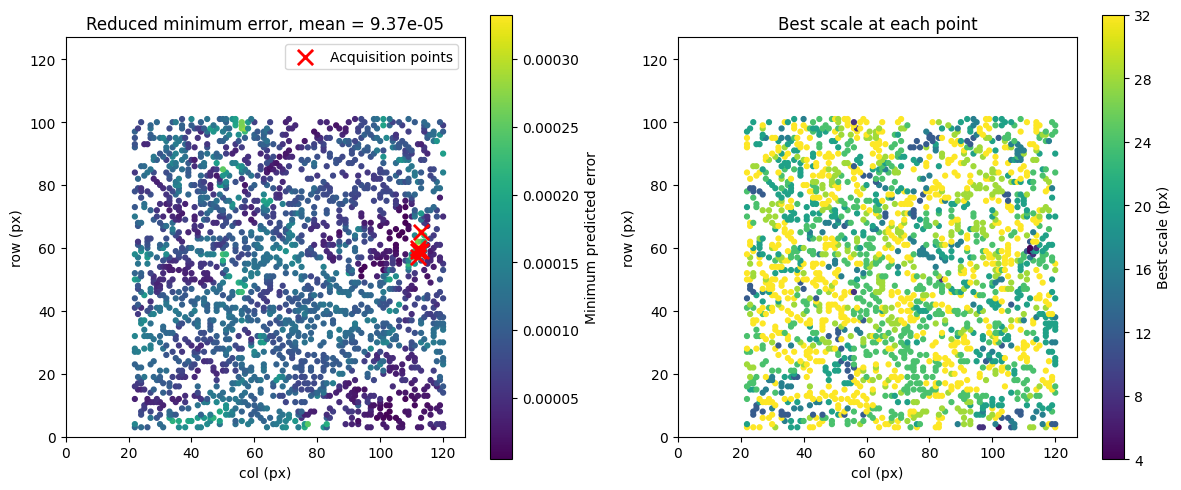

In [6]:
reduced_errors_to_plot = np.asarray(output_dict["reduced_errors"][plot_iteration])
reduced_coords_to_plot = np.asarray(output_dict["reduced_coords"][plot_iteration])
train_idx_iter = np.asarray(output_dict["train_indices"][plot_iteration], dtype=int)

# Sanity check: the IV script stores the reduction in point order, so position i is point i.
assert np.array_equal(reduced_coords_to_plot[:, :2].astype(int), point_coords)

aq_ind, _ = distance_acq_fn(reduced_errors_to_plot, beta=1, lambda_=1,
                            sample_next_points=points_per_iteration, exclude_indices=train_idx_iter)
aq_ind = np.asarray(aq_ind, dtype=int).reshape(-1)

print(f"Plotting iteration {plot_iteration} from {Path(output_file).name}")
plot_reduced_errors_and_scales(reduced_errors_to_plot, reduced_coords_to_plot, aq_indices=aq_ind)

## Confirm that the next set of `aq_ind` is used by the program

In [7]:
next_iteration = plot_iteration + 1
train_idx_next_iter = np.asarray(output_dict["train_indices"][next_iteration], dtype=int)
added = train_idx_next_iter[len(train_idx_iter):]
print("distance_acq_fn picks:", np.sort(aq_ind).tolist())
print("added to training:    ", np.sort(added).tolist())
if acquisition == "distance":
    print("match:", np.array_equal(np.sort(aq_ind), np.sort(added)))
else:
    print("(random run: the added points are random, so they are not expected to match)")

# Image (row, col) and best scale of the points that were added
print(np.c_[added, point_coords[added], reduced_coords_to_plot[added, 2].astype(int)])

distance_acq_fn picks: [1118, 1168, 1169, 1191, 1292]
added to training:     [1118, 1168, 1169, 1191, 1292]
match: True
[[1191   60  112    4]
 [1168   59  112    4]
 [1292   65  113   16]
 [1169   59  113   16]
 [1118   57  112   16]]


# Get original data

Same preprocessing as `iv_acqfn_script.py`: offset applied, plane removed then z-scored image, border-padded
WS × WS patches with a validity mask, Savitzky-Golay smoothed IV curves, and `pad` multiscale augmentation.

In [8]:
data = load_random_iv(iv_dir / "content" / "V3_IV_map_1d2um_0002.h5", iv_dir / "content" / "V3_IV_spec_1d2um_0003.h5")
assert np.array_equal(data["coords"], output_dict["recorded_coords"][0])
coords = apply_offset(data["coords"], offset)
assert np.array_equal(coords, point_coords)

full_image = Norm_G(data=flatten_image(data["topo"])).normalize()
spectra_all = smooth_spectra(data["iv"]).astype(np.float32)
v_step = data["v_step"]
patches, border_masks = get_padded_subimages(full_image, coords, WS)
full_image.shape, patches.shape, spectra_all.shape

get_padded_subimages: 396 of 2001 patches reach the image border (padded, mask = 0)


((128, 128), (2001, 32, 32), (2001, 256))

In [9]:
aug_scales = [int(s) for s in scales_saved if s != WS]
images_aug, spectra_aug, scale_coordinates = augment_with_mask(
    np.arange(N), patches, border_masks, spectra_all, coords, aug_scales)
print(images_aug.shape, scale_coordinates.shape)   # rows in blocks of N, one block per scale; (row, col, scale)

Augmented images shape: (16008, 32, 32), Augmented spectra shape: (16008, 256), Augmented coordinates shape: (16008, 3)
Augmented images shape: (16008, 32, 32), Augmented spectra shape: (16008, 256), Augmented coordinates shape: (16008, 3)
(16008, 2, 32, 32) (16008, 3)


## Acquired points at `plot_iteration`: patches and IV curves

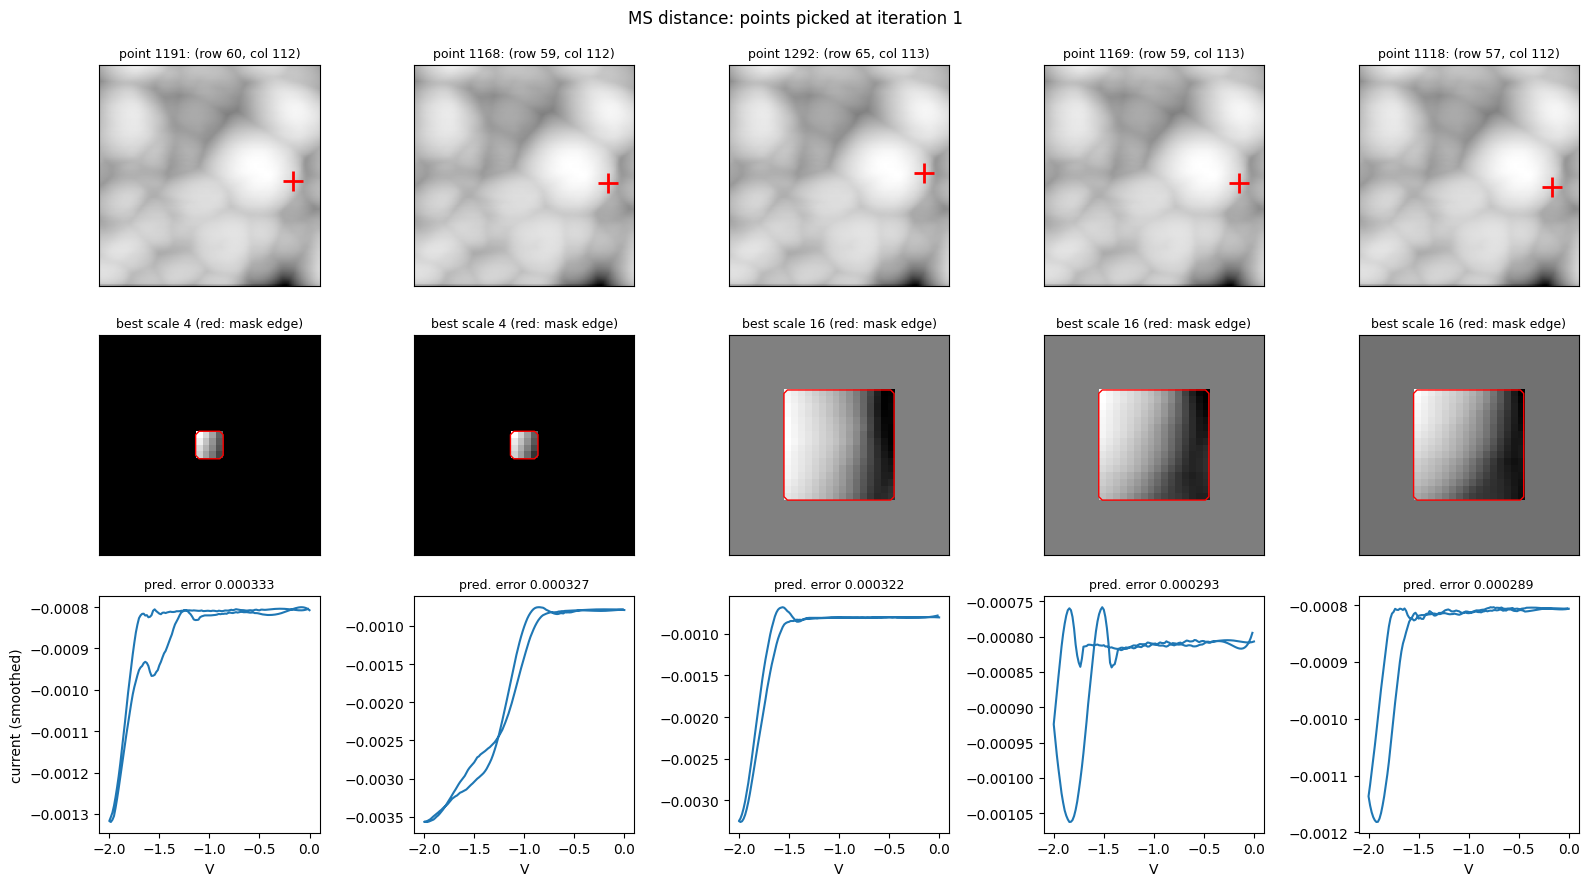

In [10]:
show = aq_ind[:points_per_iteration]
fig, axes = plt.subplots(3, len(show), figsize=(3.2 * len(show), 9), squeeze=False)
for j, p in enumerate(show):
    best_scale = int(reduced_coords_to_plot[p, 2])
    row = list(scales_saved).index(best_scale) * N + p
    r, c = point_coords[p]

    axes[0, j].imshow(full_image, origin="lower", cmap="gray")
    axes[0, j].plot(c, r, "r+", ms=14, mew=2)
    axes[0, j].set_title(f"point {p}: (row {r}, col {c})", fontsize=9)
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])

    axes[1, j].imshow(images_aug[row, 0], origin="lower", cmap="gray")
    axes[1, j].contour(images_aug[row, 1], levels=[0.5], colors="r", linewidths=1)
    axes[1, j].set_title(f"best scale {best_scale} (red: mask edge)", fontsize=9)
    axes[1, j].set_xticks([]); axes[1, j].set_yticks([])

    axes[2, j].plot(v_step, spectra_all[p])
    axes[2, j].set_xlabel("V")
    axes[2, j].set_title(f"pred. error {reduced_errors_to_plot[p]:.3g}", fontsize=9)
axes[2, 0].set_ylabel("current (smoothed)")
fig.suptitle(f"{scale_type.upper()} {acquisition}: points picked at iteration {plot_iteration}")
fig.tight_layout()
plt.show()

# Plot 3D

In [11]:
predicted_errors = np.asarray(output_dict["predicted_errors_all"][plot_iteration]).reshape(-1)
assert len(predicted_errors) == len(scale_coordinates)

plot_aq_ind, plot_aq_fn = distance_acq_fn(predicted_errors, beta=1, lambda_=1, sample_next_points=10,
                                          exclude_indices=[])
print("Shape of plot_aq_fn:", np.shape(plot_aq_fn))
print("Shape of plot_aq_ind:", np.shape(plot_aq_ind))

Shape of plot_aq_fn: (16008,)
Shape of plot_aq_ind: (10,)


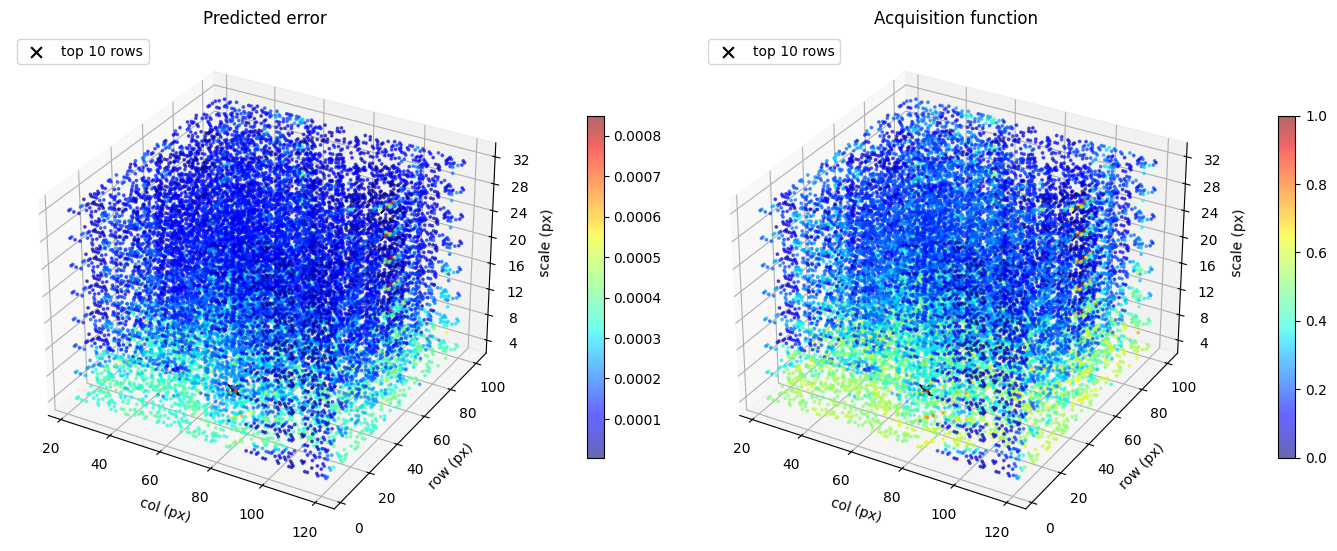

In [12]:
# Matplotlib 3D. nnerror's plot_error_prediction_3d needs a full regular grid (nx*ny*nz points), which the
# 2001 random IV points do not form, so the same two panels are drawn here as a plain 3D scatter.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

aq_fn_flat = np.asarray(plot_aq_fn).reshape(-1)
top = np.asarray(plot_aq_ind, dtype=int).reshape(-1)
fig = plt.figure(figsize=(14, 6))
for k, (vals, name) in enumerate(((predicted_errors, "Predicted error"), (aq_fn_flat, "Acquisition function"))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    sc = ax.scatter(scale_coordinates[:, 1], scale_coordinates[:, 0], scale_coordinates[:, 2], c=vals,
                    cmap="jet", s=3, alpha=0.6)
    ax.scatter(scale_coordinates[top, 1], scale_coordinates[top, 0], scale_coordinates[top, 2],
               c="k", marker="x", s=60, label="top 10 rows")
    ax.set_xlabel("col (px)"); ax.set_ylabel("row (px)"); ax.set_zlabel("scale (px)")
    ax.set_zticks(list(scales_saved))
    ax.set_title(name)
    ax.legend(loc="upper left")
    fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.1)
plt.tight_layout()
plt.show()

In [13]:
# Interactive 3D (plotly.js from a CDN; drag to rotate). Dropdown: predicted vs true error.
# Red markers: the points acquired at this iteration, at their best scale.
# True errors are saved for the test rows only; training rows are filled with the median (shown grey-ish).
r_test = (np.arange(S)[:, None] * N + test_indices_arr[plot_iteration][None, :]).ravel()
true_err_all = np.full(N * S, np.nan, dtype=np.float32)
true_err_all[r_test] = output_dict["im2spec_test_mismatches"][plot_iteration]

error_maps = {
    "predicted error": predicted_errors.reshape(S, N),
    "true im2spec error (test points; train = median)": np.nan_to_num(true_err_all, nan=np.nanmedian(true_err_all)).reshape(S, N),
}

html = error_3d_html(
    point_coords, [int(s) for s in scales_saved], error_maps,
    highlight={"acquired": (aq_ind, reduced_coords_to_plot[aq_ind, 2], "red", "x"),
               "training points": (train_idx_iter, None, "rgba(0,0,0,0.25)", None)},
    title=f"{scale_type.upper()} {acquisition}, iteration {plot_iteration}",
)
html_file = iv_dir / f"error_3d_{scale_type}_{acquisition}_iter{plot_iteration}.html"
html_file.write_text(html)
print("saved", html_file.name)
show_html_iframe(html)

saved error_3d_ms_distance_iter1.html


/home/cloud/.local/lib/python3.10/site-packages/IPython/core/display.py:475: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


# Visualize spatial coords

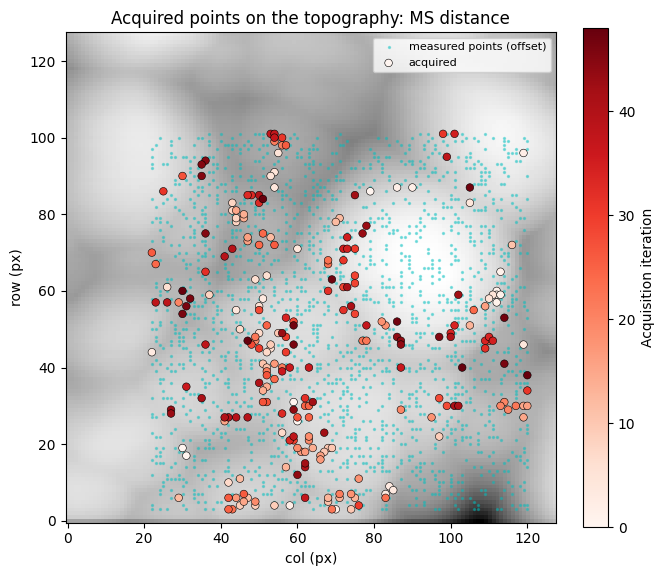

In [14]:
train_indices = output_dict["train_indices"]
initial = set(train_indices[0].tolist())
acquired_indices = np.asarray([i for i in train_indices[-1] if i not in initial], dtype=int)
acq_coords = point_coords[acquired_indices]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(full_image, origin="lower", cmap="gray")
ax.scatter(point_coords[:, 1], point_coords[:, 0], s=2, c="c", alpha=0.4, label="measured points (offset)")
sc = ax.scatter(acq_coords[:, 1], acq_coords[:, 0], c=np.arange(len(acq_coords)) // points_per_iteration,
                cmap="Reds", marker="o", s=30, edgecolors="k", linewidths=0.4, label="acquired")
plt.colorbar(sc, ax=ax, label="Acquisition iteration", fraction=0.046)
ax.set_xlabel("col (px)"); ax.set_ylabel("row (px)")
ax.set_title(f"Acquired points on the topography: {scale_type.upper()} {acquisition}")
ax.legend(loc="upper right", fontsize=8)
plt.show()

mean within-batch pairwise distance: median 37.8 px, min 3.6, max 64.8
batches with all points within 5 px of each other: 1 of 49


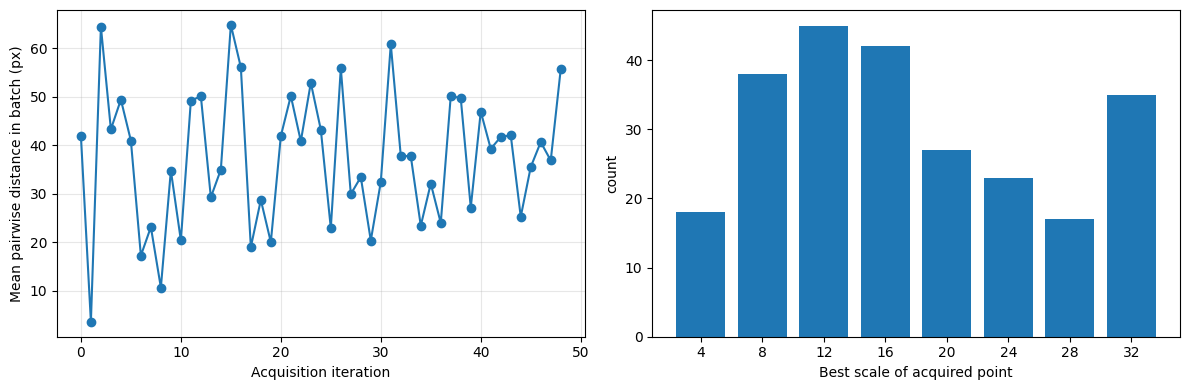

In [15]:
# Spatial spread of each acquired batch: mean pairwise distance (px) within the batch
batches = acquired_indices.reshape(-1, points_per_iteration)
spread = [np.mean([np.hypot(*(point_coords[a] - point_coords[b])) for k, a in enumerate(bt) for b in bt[k + 1:]])
          for bt in batches]
print(f"mean within-batch pairwise distance: median {np.median(spread):.1f} px, min {np.min(spread):.1f}, max {np.max(spread):.1f}")
print("batches with all points within 5 px of each other:", int(np.sum(np.asarray(spread) < 5)), "of", len(batches))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(len(spread)), spread, marker="o")
ax[0].set_xlabel("Acquisition iteration"); ax[0].set_ylabel("Mean pairwise distance in batch (px)")
ax[0].grid(True, alpha=0.3)
best_scale_acq = np.array([output_dict["reduced_coords"][i // points_per_iteration][p, 2]
                           for i, p in enumerate(acquired_indices)])
vals, counts = np.unique(best_scale_acq, return_counts=True)
ax[1].bar([str(int(x)) for x in vals], counts)
ax[1].set_xlabel("Best scale of acquired point"); ax[1].set_ylabel("count")
fig.tight_layout()
plt.show()